# Notebook 04 (Kaggle edition) — Baseline-01
Solar Filament Segmentation Challenge 2026 — runs on **Kaggle Notebooks** (no Colab, no Drive, no secrets).

**Three modes, one notebook (switch `RUN_MODE` in the CONFIG cell):**
* `"SMOKE"` -> the smoke test from Notebook 03 (24 train / 8 val images, 512 px, 20 epochs). NOT a result.
* `"PILOT"` -> dress rehearsal of the real run: ALL images, 1024 px, batch 4, but only **3 epochs**. NOT a result.
  Its job is to measure real memory use, real time per epoch, data-loading stalls, checkpoint-saving overhead and the
  full-validation-set evaluation time, and to project the cost of the 50-epoch run.
* `"FULL"`  -> the real Baseline-01 (all images, 1024 px, 50 epochs).
Recommended order: SMOKE (done) -> PILOT -> FULL.

**Before running (Kaggle side panel):**
1. *Add Input* -> the competition `filament-segmentation-2026` (read automatically from `/kaggle/input`).
2. *Session options -> Accelerator* -> GPU (T4 x2 or P100). The notebook uses ONE GPU (cuda:0) and refuses to run on CPU.

**Unchanged from Notebook 03 (controlled experiment):** U-Net base 32, Adam, BCE+Dice, date-grouped 80/20 split
(seed 42), flips-only augmentation, threshold 0.5, first-record GT, connected components, official many-to-many PQ.

**Saving / resuming on Kaggle:** files in `/kaggle/working` are kept only when you *Save Version* (Save & Run All) and are lost
when the session ends otherwise. If a session stops mid-training, *Add Input* -> your previous version's **Notebook output**
and run again: the notebook finds `latest_checkpoint.pth` in `/kaggle/input` and resumes from it.

**Honesty rule:** the report says "ALL N EPOCHS COMPLETED" only if all configured epochs actually finished.

In [4]:
# ============================================================
# CONFIGURATION — the only cell you should need to edit
# ============================================================

# Competition data: attach it via "Add Input". Path is auto-detected (notebooks 1 and 2 used the first one).
KAGGLE_DATA_CANDIDATES = [
    "/kaggle/input/competitions/filament-segmentation-2026",
    "/kaggle/input/filament-segmentation-2026",
]

RUN_MODE = "FULL"               # <<< REAL Baseline-01.  ("SMOKE" | "PILOT" | "FULL", see the markdown cell above)
assert RUN_MODE in ("SMOKE", "PILOT", "FULL"), "RUN_MODE must be SMOKE, PILOT or FULL"
DEBUG_MODE = (RUN_MODE == "SMOKE")   # reduced-image-count shortcuts exist ONLY in SMOKE mode

OUTPUT_DIR = "/kaggle/working"  # kept only if you "Save Version"; see markdown above

SEED = 42
RESUME = True                   # resume from latest valid checkpoint if one exists

# ---- experiment parameters (Baseline-01) — same field names as Notebook 03 ----
CFG = {
    "experiment_id": "Baseline-01" if RUN_MODE == "FULL" else f"Baseline-01-{RUN_MODE}",
    "train_resolution": 512 if DEBUG_MODE else 1024,
    "batch_size": 2 if DEBUG_MODE else 4,
    "epochs": {"SMOKE": 20, "PILOT": 3, "FULL": 50}[RUN_MODE],
    "lr": 1e-3,
    "weight_decay": 1e-5,
    "model": "UNet-base32",
    "loss": "BCE+Dice",
    "prob_threshold": 0.5,       # single configurable baseline threshold (NOT tuned)
    "min_instance_px": 0,        # no size filtering in the baseline
    "debug_n_train": 24,         # smoke-test only
    "debug_n_val": 8,            # smoke-test only
    # ---- run-infrastructure settings (do not change the methodology) ----
    "use_amp": True,             # automatic mixed precision for training / val loss
    "num_workers": None,         # None -> min(4, cpu_count)
    "pq_eval_every": 10,         # monitor val PQ every N epochs (0 = only final). Monitoring only.
    "snapshot_every": 10,        # keep a full-state snapshot every N epochs
    "ckpt_every": 2,             # write latest_checkpoint.pth every N epochs (and always at the last epoch)
    "fsync_checkpoints": False,  # fsync was a suspected cause of slow saves on Kaggle disk; atomic rename is kept
}

print(f"RUN_MODE={RUN_MODE} (DEBUG_MODE={DEBUG_MODE}) | resolution={CFG['train_resolution']} "
      f"| epochs={CFG['epochs']} | batch={CFG['batch_size']} | AMP={CFG['use_amp']}")

RUN_MODE=FULL (DEBUG_MODE=False) | resolution=1024 | epochs=50 | batch=4 | AMP=True


In [5]:
import os, sys, json, random, re, warnings, math, shutil, time, hashlib, platform, gc, datetime
from pathlib import Path
from collections import defaultdict, Counter

try:
    import pycocotools
except ImportError:
    !pip -q install pycocotools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from tqdm.auto import tqdm
from pycocotools import mask as mask_utils

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ---- GPU is REQUIRED. No silent CPU fallback. ----
if not torch.cuda.is_available():
    raise RuntimeError(
        "No CUDA GPU is available. This notebook will NOT fall back to CPU.\n"
        "Fix: in the Kaggle right-hand panel open Session options -> Accelerator -> choose GPU T4 x2 or P100, "
        "then run again.")
DEVICE = torch.device("cuda:0")
N_GPUS_VISIBLE = torch.cuda.device_count()
print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | device {DEVICE}")
print(f"GPU: {torch.cuda.get_device_name(0)} | visible GPUs: {N_GPUS_VISIBLE} "
      f"| this notebook uses ONLY cuda:0 (no DataParallel)")

if CFG["num_workers"] is None:
    CFG["num_workers"] = min(4, os.cpu_count() or 2)

# ---- output location (Kaggle working dir) ----
OUT_ROOT = Path(OUTPUT_DIR); OUT_ROOT.mkdir(parents=True, exist_ok=True)
OUT = OUT_ROOT / {"SMOKE": "debug", "PILOT": "pilot", "FULL": "full"}[RUN_MODE]
OUT.mkdir(parents=True, exist_ok=True)
IN_KAGGLE = Path("/kaggle/input").exists()
print("Running on Kaggle:", IN_KAGGLE, "| Outputs:", OUT)
print("NOTE: /kaggle/working is kept only when you Save Version (Save & Run All); lost when the session ends otherwise.")

# ---- bring a previous version's checkpoints into /kaggle/working (resume across sessions) ----
RESUME_FILES = ["latest_checkpoint.pth", "latest_checkpoint_prev.pth", "baseline_best.pth",
                "baseline_best_meta.json", "training_history.csv", "split_metadata.csv"]

def import_previous_output():
    if (OUT / "latest_checkpoint.pth").exists() or not IN_KAGGLE:
        return
    hits = [p for p in Path("/kaggle/input").rglob("latest_checkpoint*.pth") if p.parent.name == OUT.name]
    if not hits:
        return
    src = max(hits, key=lambda p: p.stat().st_mtime).parent
    print(f">>> Found a previous run's checkpoints in {src} — copying them into {OUT} for resume")
    for f in RESUME_FILES + [p.name for p in src.glob("checkpoint_epoch_*.pth")]:
        if (src / f).exists() and not (OUT / f).exists():
            shutil.copyfile(src / f, OUT / f)

import_previous_output()
print("DataLoader workers:", CFG["num_workers"])

Python 3.13.15 | torch 2.11.0+cu128 | device cuda:0
GPU: Tesla T4 | visible GPUs: 2 | this notebook uses ONLY cuda:0 (no DataParallel)
Running on Kaggle: True | Outputs: /kaggle/working/full
NOTE: /kaggle/working is kept only when you Save Version (Save & Run All); lost when the session ends otherwise.
DataLoader workers: 4


In [6]:
# ============================================================
# DATA DISCOVERY on Kaggle (/kaggle/input) — same discovery logic as Notebook 03
# ============================================================

def acquire_data_root():
    for c in KAGGLE_DATA_CANDIDATES:
        if Path(c).exists():
            return Path(c)
    base = Path("/kaggle/input")
    if base.exists() and any(base.rglob("train_images")):
        print("WARNING: standard path not found; using /kaggle/input and auto-discovery.")
        return base
    raise FileNotFoundError(
        "Competition data not found under /kaggle/input.\n"
        "Fix: right-hand panel -> Add Input -> search 'filament-segmentation-2026' -> Add.")

DATA_ROOT = acquire_data_root()
print("DATA_ROOT:", DATA_ROOT)

IMG_EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

def discover_dataset(root):
    """Find train/test image dirs and the COCO annotation JSON. Fail loudly."""
    img_dirs = []
    for d in sorted({p.parent for p in root.rglob("*") if p.suffix.lower() in IMG_EXTS}):
        n = sum(1 for p in d.iterdir() if p.suffix.lower() in IMG_EXTS)
        img_dirs.append((d, n))
        print(f"  image dir: {d.relative_to(root)}  ({n} images)")
    train_cands = [d for d, _ in img_dirs
                   if "train" in str(d).lower() and "test" not in str(d).lower()]
    test_cands = [d for d, _ in img_dirs
                  if "test" in str(d).lower() and "train" not in str(d).lower()]
    if len(train_cands) != 1 or len(test_cands) != 1:
        raise RuntimeError(
            f"Ambiguous dataset layout. train candidates={train_cands}, "
            f"test candidates={test_cands}. Inspect the listing above.")
    coco = None
    for p in root.rglob("*.json"):
        try:
            with open(p) as f:
                d = json.load(f)
            if isinstance(d, dict) and "images" in d and "annotations" in d:
                coco = p; break
        except Exception:
            pass
    if coco is None:
        raise RuntimeError(f"No COCO-style annotation JSON found under {root}")
    return train_cands[0], test_cands[0], coco

TRAIN_DIR, TEST_DIR, ANN_PATH = discover_dataset(DATA_ROOT)

train_paths = sorted(p for p in TRAIN_DIR.iterdir() if p.suffix.lower() in IMG_EXTS)
test_paths  = sorted(p for p in TEST_DIR.iterdir()  if p.suffix.lower() in IMG_EXTS)
name_to_path = {p.name: p for p in train_paths}

print(f"\ntrain images: {len(train_paths)} | test images: {len(test_paths)}")
print(f"annotations: {ANN_PATH.name}")
assert len(train_paths) > 0 and len(test_paths) > 0

DATA_ROOT: /kaggle/input/competitions/filament-segmentation-2026
  image dir: MAGFiLO_1.0_Kaggle_2026/test/test_images  (180 images)
  image dir: MAGFiLO_1.0_Kaggle_2026/train/train_images  (707 images)

train images: 707 | test images: 180
annotations: MAGFiLO_1.0_Annotations_kaggle2026_train.json


In [7]:
# ============================================================
# ANNOTATIONS + BASELINE GT REPRESENTATION  (unchanged from Notebook 03)
# Baseline target = FIRST annotation record per file (sorted by id).
# ============================================================

def load_annotations(path):
    with open(path) as f:
        coco = json.load(f)
    images_info = {im["id"]: im for im in coco["images"]}
    anns_by_image = defaultdict(list)
    for a in coco["annotations"]:
        anns_by_image[a["image_id"]].append(a)
    return coco, images_info, anns_by_image

COCO, images_info, anns_by_image = load_annotations(ANN_PATH)
print(f"JSON records: {len(images_info)} | annotations: {len(COCO['annotations'])}")

file_to_records = defaultdict(list)
for img_id, info in images_info.items():
    fname = Path(info["file_name"]).name
    if fname in name_to_path:
        file_to_records[fname].append(img_id)

missing = len(images_info) - sum(len(v) for v in file_to_records.values())
if missing:
    raise RuntimeError(f"{missing} JSON records reference files not on disk")

file_to_primary = {f: sorted(ids)[0] for f, ids in file_to_records.items()}
primary_ids = sorted(file_to_primary.values())
print(f"physical files: {len(file_to_primary)} | primary records: {len(primary_ids)}")

def ann_to_mask(ann, h, w):
    m = np.zeros((h, w), np.uint8)
    for poly in ann["segmentation"]:
        pts = np.asarray(poly, np.float64).reshape(-1, 2)
        cv2.fillPoly(m, [np.round(pts).astype(np.int32)], 1)
    return m.astype(bool)

def build_gt_masks(img_id):
    """Full-resolution instance masks for one record."""
    info = images_info[img_id]
    masks = [ann_to_mask(a, info["height"], info["width"])
             for a in anns_by_image[img_id]]
    masks = [m for m in masks if m.any()]
    if not masks:
        raise ValueError(f"Record {img_id} has no non-empty GT masks")
    return masks

def load_image(path):
    img = np.array(Image.open(path))
    if img.ndim == 3:
        img = img[..., :3].mean(axis=2)
    return img.astype(np.float32)

JSON records: 1154 | annotations: 8199
physical files: 707 | primary records: 707


In [8]:
# ============================================================
# OFFICIAL EVALUATOR REPRODUCTION
# Many-to-many matching: EVERY (pred, gt) pair with IoU > 0.5 (STRICT >)
# is a TP and contributes its IoU to the numerator.
# FP = pred with zero qualifying matches; FN = gt with zero.
# PQ = sum(TP IoUs) / (TP + 0.5 FP + 0.5 FN)
# Diagnostics (one-to-many / many-to-one) use overlap > 0.
#
# Only change vs Notebook 03: the pairwise IoU/Dice loop skips pairs whose
# bounding boxes do not intersect and only intersects the bbox overlap region.
# Results are mathematically identical (verified against the original
# implementation in the equivalence test below); it is just much faster.
# ============================================================

def _bbox(m):
    rows = np.flatnonzero(m.any(axis=1)); cols = np.flatnonzero(m.any(axis=0))
    if len(rows) == 0:
        return (0, 0, 0, 0)
    return (rows[0], rows[-1] + 1, cols[0], cols[-1] + 1)

def iou_and_dice_matrix(pred_masks, gt_masks):
    n_p, n_g = len(pred_masks), len(gt_masks)
    iou = np.zeros((n_p, n_g)); dce = np.zeros((n_p, n_g))
    pb = [_bbox(p) for p in pred_masks]; gb = [_bbox(g) for g in gt_masks]
    pa = [int(p.sum()) for p in pred_masks]; ga = [int(g.sum()) for g in gt_masks]
    for i, p in enumerate(pred_masks):
        py0, py1, px0, px1 = pb[i]
        for j, g in enumerate(gt_masks):
            gy0, gy1, gx0, gx1 = gb[j]
            y0, y1 = max(py0, gy0), min(py1, gy1)
            x0, x1 = max(px0, gx0), min(px1, gx1)
            if y0 >= y1 or x0 >= x1:
                continue
            inter = int(np.logical_and(p[y0:y1, x0:x1], g[y0:y1, x0:x1]).sum())
            if inter == 0:
                continue
            iou[i, j] = inter / (pa[i] + ga[j] - inter)
            dce[i, j] = 2 * inter / (pa[i] + ga[j])
    return iou, dce

def compute_official_pq(gt_masks, pred_masks):
    if len(gt_masks) == 0 and len(pred_masks) == 0:
        return {"PQ": 1.0, "TP": 0, "FP": 0, "FN": 0,
                "tp_ious": [], "tp_dices": [],
                "one_to_many": 0, "many_to_one": 0}
    iou, dce = iou_and_dice_matrix(pred_masks, gt_masks)
    hit = iou > 0.5                                   # STRICT >
    tp_ious = iou[hit].tolist()
    tp_dices = dce[hit].tolist()
    tp = len(tp_ious)
    fp = int((hit.sum(axis=1) == 0).sum()) if len(pred_masks) else 0
    fn = int((hit.sum(axis=0) == 0).sum()) if len(gt_masks) else 0
    denom = tp + 0.5 * fp + 0.5 * fn
    overlap = iou > 0
    one_to_many = int((overlap.sum(axis=0) > 1).sum())   # GT hit by multiple preds
    many_to_one = int((overlap.sum(axis=1) > 1).sum())   # pred hitting multiple GTs
    return {"PQ": (sum(tp_ious) / denom) if denom > 0 else 0.0,
            "TP": tp, "FP": fp, "FN": fn,
            "tp_ious": tp_ious, "tp_dices": tp_dices,
            "one_to_many": one_to_many, "many_to_one": many_to_one}

# ---------------- MANDATORY UNIT TESTS (same 7 as Notebook 03) ----------------
def _box(y0, y1, x0, x1, hw=64):
    m = np.zeros((hw, hw), bool); m[y0:y1, x0:x1] = True; return m

def run_metric_tests():
    results = []
    g = _box(10, 20, 10, 30)                       # 10x20 = 200 px

    r = compute_official_pq([g], [g.copy()])
    results.append(("T1 perfect -> PQ=1", abs(r["PQ"] - 1.0) < 1e-9))

    half = _box(10, 20, 10, 20)                    # IoU = 0.5 exactly
    r = compute_official_pq([g], [half])
    results.append(("T2 IoU==0.5 not TP", r["TP"] == 0 and r["FP"] == 1 and r["FN"] == 1))

    most = _box(10, 20, 10, 24)                    # IoU = 0.7
    r = compute_official_pq([g], [most])
    results.append(("T3 IoU>0.5 is TP", r["TP"] == 1 and r["FP"] == 0 and r["FN"] == 0))

    p1 = _box(10, 20, 10, 27); p2 = _box(10, 20, 12, 30)
    r = compute_official_pq([g], [p1, p2])
    results.append(("T4 1 GT + 2 preds -> TP=2 FP=0 FN=0",
                    r["TP"] == 2 and r["FP"] == 0 and r["FN"] == 0))

    g1 = _box(10, 20, 10, 30); g2 = _box(10, 20, 8, 32); pred = _box(10, 20, 9, 31)
    r = compute_official_pq([g1, g2], [pred])
    results.append(("T5 2 GT + 1 pred -> TP=2 FP=0 FN=0",
                    r["TP"] == 2 and r["FP"] == 0 and r["FN"] == 0))

    r = compute_official_pq([g], [])
    results.append(("T6 no preds -> FN=1, PQ=0", r["FN"] == 1 and r["PQ"] == 0.0))

    r = compute_official_pq([], [g])
    results.append(("T7 no GT -> FP=1, PQ=0", r["FP"] == 1 and r["PQ"] == 0.0))

    all_ok = True
    for name, ok in results:
        print(f"  {'PASS' if ok else 'FAIL'}  {name}")
        all_ok &= ok
    if not all_ok:
        raise AssertionError("Metric unit tests FAILED — do not proceed")
    print("All 7 metric tests passed.")

run_metric_tests()

# ---------------- EQUIVALENCE TEST: fast matrix == original Notebook-03 matrix ----------------
def _iou_and_dice_matrix_reference(pred_masks, gt_masks):
    """Verbatim original implementation from Notebook 03 (slow, full-frame)."""
    n_p, n_g = len(pred_masks), len(gt_masks)
    iou = np.zeros((n_p, n_g)); dce = np.zeros((n_p, n_g))
    for i, p in enumerate(pred_masks):
        ps = p.sum()
        for j, g in enumerate(gt_masks):
            inter = np.logical_and(p, g).sum()
            if inter == 0:
                continue
            gs = g.sum()
            iou[i, j] = inter / (ps + gs - inter)
            dce[i, j] = 2 * inter / (ps + gs)
    return iou, dce

def run_equivalence_test(n_trials=40, hw=96):
    rng = np.random.RandomState(0)
    def rand_mask():
        m = np.zeros((hw, hw), np.uint8)
        for _ in range(rng.randint(1, 4)):
            y, x = rng.randint(0, hw - 8, 2); h, w = rng.randint(2, 30, 2)
            m[y:y + h, x:x + w] = 1
        return m.astype(bool)
    for _ in range(n_trials):
        P = [rand_mask() for _ in range(rng.randint(0, 6))]
        G = [rand_mask() for _ in range(rng.randint(0, 6))]
        a = iou_and_dice_matrix(P, G); b = _iou_and_dice_matrix_reference(P, G)
        assert np.allclose(a[0], b[0]) and np.allclose(a[1], b[1]), "fast IoU/Dice differs from original"
    print(f"Equivalence test passed: fast evaluator == original on {n_trials} random cases.")

run_equivalence_test()

  PASS  T1 perfect -> PQ=1
  PASS  T2 IoU==0.5 not TP
  PASS  T3 IoU>0.5 is TP
  PASS  T4 1 GT + 2 preds -> TP=2 FP=0 FN=0
  PASS  T5 2 GT + 1 pred -> TP=2 FP=0 FN=0
  PASS  T6 no preds -> FN=1, PQ=0
  PASS  T7 no GT -> FP=1, PQ=0
All 7 metric tests passed.
Equivalence test passed: fast evaluator == original on 40 random cases.


In [9]:
# ============================================================
# RLE (pycocotools, Fortran order, 2048x2048)  — kept for the later submission notebook
# ============================================================

def encode_rle(mask):
    rle = mask_utils.encode(np.asfortranarray(mask.astype(np.uint8)))
    rle["counts"] = rle["counts"].decode("utf-8")
    return rle

def decode_rle(rle):
    r = dict(rle)
    if isinstance(r["counts"], str):
        r["counts"] = r["counts"].encode("utf-8")
    return mask_utils.decode(r).astype(bool)

_t = np.zeros((2048, 2048), bool)
_t[100:130, 400:900] = True; _t[1500:1510, 30:80] = True
_rt = decode_rle(encode_rle(_t))
assert _rt.shape == (2048, 2048) and (_rt == _t).all(), "RLE round-trip mismatch"
assert decode_rle(encode_rle(np.zeros((2048, 2048), bool))).sum() == 0
print("RLE round-trip checks passed (2048x2048, incl. empty mask)")

RLE round-trip checks passed (2048x2048, incl. empty mask)


In [10]:
# ============================================================
# SPLIT — date-grouped 80/20 (Notebook 02 A3). Same function, same seed as Notebook 03.
# ============================================================

FN_RE = re.compile(r"^(\d{4})(\d{2})(\d{2})\d{6}([A-Za-z])h\.", re.I)

def create_split(primary_ids, val_frac=0.2, seed=SEED):
    rows = []
    for img_id in primary_ids:
        fname = Path(images_info[img_id]["file_name"]).name
        m = FN_RE.match(fname)
        if not m:
            raise ValueError(f"Unparseable filename: {fname}")
        rows.append({"img_id": img_id, "file": fname,
                     "date": f"{m[1]}-{m[2]}-{m[3]}", "station": m[4].upper()})
    df = pd.DataFrame(rows)
    dates = sorted(df["date"].unique())
    rng = random.Random(seed); rng.shuffle(dates)
    n_val_dates = int(round(len(dates) * val_frac))
    val_dates = set(dates[:n_val_dates])
    df["split"] = df["date"].map(lambda d: "val" if d in val_dates else "train")
    return df

split_df = create_split(primary_ids)
train_ids = split_df.loc[split_df.split == "train", "img_id"].tolist()
val_ids   = split_df.loc[split_df.split == "val", "img_id"].tolist()

if DEBUG_MODE:                       # smoke-test shortcut — must be OFF for Baseline-01
    train_ids = train_ids[:CFG["debug_n_train"]]
    val_ids   = val_ids[:CFG["debug_n_val"]]

SPLIT_HASH = hashlib.sha1(",".join(sorted(
    split_df.loc[split_df.split == "val", "file"])).encode()).hexdigest()[:12]

split_df.to_csv(OUT / "split_metadata.csv", index=False)
print(f"train: {len(train_ids)} | val: {len(val_ids)} (date-grouped) | split hash: {SPLIT_HASH}")
assert not set(split_df[split_df.split == "train"].date) & \
           set(split_df[split_df.split == "val"].date)

train: 568 | val: 139 (date-grouped) | split hash: 0cc2d729a5b1


In [11]:
# ============================================================
# DATASET — fixed-size tensors. Preprocessing and augmentation (h/v flips only)
# are IDENTICAL to Notebook 03.
# ============================================================

class FilamentDataset(Dataset):
    def __init__(self, record_ids, resolution, augment=False):
        self.ids = record_ids
        self.res = resolution
        self.augment = augment

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        img_id = self.ids[idx]
        info = images_info[img_id]
        fname = Path(info["file_name"]).name
        img = load_image(name_to_path[fname])
        h, w = img.shape

        gt = np.zeros((h, w), bool)
        for a in anns_by_image[img_id]:
            gt |= ann_to_mask(a, h, w)

        img = cv2.resize(img, (self.res, self.res), interpolation=cv2.INTER_AREA)
        gt = cv2.resize(gt.astype(np.uint8), (self.res, self.res),
                        interpolation=cv2.INTER_NEAREST).astype(bool)

        lo, hi = np.percentile(img, [1, 99])
        img = np.clip((img - lo) / max(hi - lo, 1e-6), 0, 1).astype(np.float32)

        if self.augment:
            if random.random() < 0.5:
                img = np.fliplr(img).copy(); gt = np.fliplr(gt).copy()
            if random.random() < 0.5:
                img = np.flipud(img).copy(); gt = np.flipud(gt).copy()

        return {"image": torch.from_numpy(img)[None],
                "mask": torch.from_numpy(gt.astype(np.float32))[None],
                "img_id": img_id}

def _worker_init(_):
    cv2.setNumThreads(0)

train_ds = FilamentDataset(train_ids, CFG["train_resolution"], augment=True)
val_ds   = FilamentDataset(val_ids, CFG["train_resolution"], augment=False)

# generator is re-seeded every epoch (SEED + epoch) so shuffling/augmentation is reproducible
# and identical whether or not the run was resumed.
train_gen = torch.Generator(); train_gen.manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True,
                          num_workers=CFG["num_workers"], pin_memory=True, drop_last=True,
                          generator=train_gen, worker_init_fn=_worker_init)
val_loader = DataLoader(val_ds, batch_size=1, shuffle=False,
                        num_workers=CFG["num_workers"], pin_memory=True,
                        worker_init_fn=_worker_init)

# sample check WITHOUT creating DataLoader iterators (avoids the dangling-worker noise seen in Notebook 03)
_s = train_ds[0]
print("sample check:", tuple(_s["image"].shape), tuple(_s["mask"].shape),
      "| train batches/epoch:", len(train_loader), "| val images:", len(val_ds))
del _s

sample check: (1, 1024, 1024) (1, 1024, 1024) | train batches/epoch: 142 | val images: 139


In [12]:
# ============================================================
# MODEL — plain U-Net (base 32), UNCHANGED.  Loss — BCE + soft Dice, UNCHANGED
# (logits are cast to float32 inside the loss so AMP cannot affect the loss math).
# ============================================================

class ConvBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

class UNet(nn.Module):
    def __init__(self, cin=1, base=32):
        super().__init__()
        self.e1, self.e2 = ConvBlock(cin, base), ConvBlock(base, base*2)
        self.e3, self.e4 = ConvBlock(base*2, base*4), ConvBlock(base*4, base*8)
        self.pool = nn.MaxPool2d(2)
        self.mid = ConvBlock(base*8, base*16)
        self.u4 = nn.ConvTranspose2d(base*16, base*8, 2, 2); self.d4 = ConvBlock(base*16, base*8)
        self.u3 = nn.ConvTranspose2d(base*8, base*4, 2, 2);  self.d3 = ConvBlock(base*8, base*4)
        self.u2 = nn.ConvTranspose2d(base*4, base*2, 2, 2);  self.d2 = ConvBlock(base*4, base*2)
        self.u1 = nn.ConvTranspose2d(base*2, base, 2, 2);    self.d1 = ConvBlock(base*2, base)
        self.out = nn.Conv2d(base, 1, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(self.pool(e1))
        e3 = self.e3(self.pool(e2)); e4 = self.e4(self.pool(e3))
        m = self.mid(self.pool(e4))
        d = self.d4(torch.cat([self.u4(m), e4], 1))
        d = self.d3(torch.cat([self.u3(d), e3], 1))
        d = self.d2(torch.cat([self.u2(d), e2], 1))
        d = self.d1(torch.cat([self.u1(d), e1], 1))
        return self.out(d)

def build_model():
    return UNet(1, 32).to(DEVICE)

def build_optimizer(model):
    return torch.optim.Adam(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])

def bce_dice_loss(logits, target, eps=1.0):
    logits = logits.float()
    bce = nn.functional.binary_cross_entropy_with_logits(logits, target)
    prob = torch.sigmoid(logits)
    inter = (prob * target).sum(dim=(2, 3))
    dice = (2 * inter + eps) / (prob.sum(dim=(2, 3)) + target.sum(dim=(2, 3)) + eps)
    return bce + (1 - dice).mean()

USE_AMP = bool(CFG["use_amp"]) and DEVICE.type == "cuda"

def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP)

def build_scaler():
    return torch.amp.GradScaler("cuda", enabled=USE_AMP)

EXPECTED_PARAMS = 7_765_409      # parameter count reported by the Notebook 03 smoke test
_tmp_model = build_model()
N_PARAMS = sum(p.numel() for p in _tmp_model.parameters())
del _tmp_model
print(f"parameters: {N_PARAMS:,} | AMP: {USE_AMP}")

parameters: 7,765,409 | AMP: True


In [13]:
# ============================================================
# INFERENCE + VALIDATION UNDER THE OFFICIAL METRIC (per-image, full 2048)
# Inference for PQ is done in FP32 (identical to Notebook 03).
# ============================================================

@torch.no_grad()
def predict_image(model, img_path, resolution):
    """Returns full-2048 probability map."""
    img = load_image(img_path)
    h, w = img.shape
    small = cv2.resize(img, (resolution, resolution), interpolation=cv2.INTER_AREA)
    lo, hi = np.percentile(small, [1, 99])
    small = np.clip((small - lo) / max(hi - lo, 1e-6), 0, 1).astype(np.float32)
    x = torch.from_numpy(small)[None, None].to(DEVICE)
    prob = torch.sigmoid(model(x))[0, 0].cpu().numpy()
    return cv2.resize(prob, (w, h), interpolation=cv2.INTER_LINEAR)

def extract_instances(prob, threshold, min_px=0):
    """Probability map -> list of boolean instance masks via connected components."""
    binary = (prob > threshold).astype(np.uint8)
    n, labels = cv2.connectedComponents(binary, connectivity=8)
    out = []
    for k in range(1, n):
        m = labels == k
        if m.sum() > min_px:
            out.append(m)
    return out

def evaluate_validation(model, ids, threshold, desc="validation"):
    """Official-metric evaluation over ALL images in `ids`."""
    model.eval()
    rows, all_tp_ious, all_tp_dices = [], [], []
    agg = Counter()
    for img_id in tqdm(ids, desc=desc, leave=False):
        fname = Path(images_info[img_id]["file_name"]).name
        gt = build_gt_masks(img_id)
        prob = predict_image(model, name_to_path[fname], CFG["train_resolution"])
        preds = extract_instances(prob, threshold, CFG["min_instance_px"])
        r = compute_official_pq(gt, preds)
        all_tp_ious += r["tp_ious"]; all_tp_dices += r["tp_dices"]
        for k in ["TP", "FP", "FN", "one_to_many", "many_to_one"]:
            agg[k] += r[k]
        rows.append({"img_id": img_id, "file": fname,
                     "n_gt": len(gt), "n_pred": len(preds),
                     "PQ": r["PQ"], "TP": r["TP"], "FP": r["FP"], "FN": r["FN"],
                     "one_to_many": r["one_to_many"], "many_to_one": r["many_to_one"],
                     "mean_tp_iou": float(np.mean(r["tp_ious"])) if r["tp_ious"] else np.nan,
                     "mean_tp_dice": float(np.mean(r["tp_dices"])) if r["tp_dices"] else np.nan})
    per_image = pd.DataFrame(rows)
    denom = agg["TP"] + 0.5 * agg["FP"] + 0.5 * agg["FN"]
    overall = {
        "PQ_pooled": float(sum(all_tp_ious) / denom) if denom else 0.0,
        "PQ_mean_per_image": float(per_image["PQ"].mean()),
        "TP": int(agg["TP"]), "FP": int(agg["FP"]), "FN": int(agg["FN"]),
        "mean_tp_iou": float(np.mean(all_tp_ious)) if all_tp_ious else 0.0,
        "mean_tp_dice": float(np.mean(all_tp_dices)) if all_tp_dices else 0.0,
        "one_to_many": int(agg["one_to_many"]), "many_to_one": int(agg["many_to_one"]),
        "n_images_evaluated": int(len(per_image)), "threshold": float(threshold),
    }
    return per_image, overall, all_tp_ious, all_tp_dices

In [14]:
# ============================================================
# CHECKPOINT UTILITIES (atomic writes; latest + previous + best; resume-safe)
# ============================================================

CKPT_BEST      = OUT / "baseline_best.pth"            # state_dict only (same format as Notebook 03)
CKPT_BEST_META = OUT / "baseline_best_meta.json"
CKPT_LATEST    = OUT / "latest_checkpoint.pth"        # full resumable state
CKPT_PREV      = OUT / "latest_checkpoint_prev.pth"   # previous latest (fallback if latest is corrupt)
HIST_CSV       = OUT / "training_history.csv"

CORE_KEYS = ["train_resolution", "batch_size", "lr", "weight_decay", "model", "loss", "use_amp"]

def cfg_core():
    return {k: CFG[k] for k in CORE_KEYS} | {"seed": SEED}

def _atomic_replace(tmp, dst):
    if CFG["fsync_checkpoints"]:
        try:
            with open(tmp, "rb") as f:
                os.fsync(f.fileno())
        except Exception:
            pass
    os.replace(tmp, dst)

def atomic_torch_save(obj, path):
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    _atomic_replace(tmp, path)

def atomic_write_text(path, text):
    tmp = path.with_name(path.name + ".tmp")
    tmp.write_text(text)
    _atomic_replace(tmp, path)

REQUIRED_CKPT_KEYS = {"epoch", "model", "optimizer", "scaler", "history", "best_val",
                      "best_epoch", "cfg_core", "split_hash", "elapsed_train_s"}

def load_checkpoint_if_valid(path):
    if not path.exists():
        return None
    try:
        ck = torch.load(path, map_location="cpu", weights_only=True)
        if not REQUIRED_CKPT_KEYS.issubset(ck.keys()):
            raise ValueError("missing keys: " + str(REQUIRED_CKPT_KEYS - set(ck.keys())))
        if not isinstance(ck["epoch"], int) or ck["epoch"] < 0:
            raise ValueError("bad epoch")
        return ck
    except Exception as e:
        print(f"  WARNING: checkpoint {path.name} is not usable ({e!r})")
        return None

def find_latest_valid_checkpoint():
    for p in (CKPT_LATEST, CKPT_PREV):
        ck = load_checkpoint_if_valid(p)
        if ck is not None:
            return p, ck
    return None, None

def save_latest_checkpoint(model, optimizer, scaler, epoch, history, best_val, best_epoch,
                           elapsed_train_s, snapshot=False):
    state = {"epoch": int(epoch), "model": model.state_dict(), "optimizer": optimizer.state_dict(),
             "scaler": scaler.state_dict(), "history": history,
             "best_val": float(best_val), "best_epoch": None if best_epoch is None else int(best_epoch),
             "cfg_core": cfg_core(), "split_hash": SPLIT_HASH,
             "elapsed_train_s": float(elapsed_train_s)}
    tmp = CKPT_LATEST.with_name(CKPT_LATEST.name + ".tmp")
    torch.save(state, tmp)
    if CFG["fsync_checkpoints"]:
        try:
            with open(tmp, "rb") as f: os.fsync(f.fileno())
        except Exception:
            pass
    if CKPT_LATEST.exists():
        os.replace(CKPT_LATEST, CKPT_PREV)       # keep one previous valid checkpoint
    os.replace(tmp, CKPT_LATEST)
    if snapshot:
        shutil.copyfile(CKPT_LATEST, OUT / f"checkpoint_epoch_{epoch:03d}.pth")

def save_best(model, epoch, val_loss):
    atomic_torch_save(model.state_dict(), CKPT_BEST)
    atomic_write_text(CKPT_BEST_META, json.dumps(
        {"best_epoch": int(epoch), "best_val_loss": float(val_loss),
         "saved_at": datetime.datetime.now().isoformat(timespec="seconds")}))

def read_best_meta():
    try:
        return json.loads(CKPT_BEST_META.read_text())
    except Exception:
        return None

print("checkpoint dir:", OUT)
_p, _ck = find_latest_valid_checkpoint()
print("latest valid checkpoint:", None if _p is None else f"{_p.name} (completed epoch {_ck['epoch']})")
del _p, _ck

checkpoint dir: /kaggle/working/full
latest valid checkpoint: None


In [15]:
# ============================================================
# PREFLIGHT — verifies everything BEFORE training. Any failure stops the run.
# ============================================================
PREFLIGHT = []
def check(name, ok, detail=""):
    PREFLIGHT.append((name, bool(ok), detail))
    print(f"  [{'PASS' if ok else 'FAIL'}] {name}" + (f"  ->  {detail}" if detail else ""))

print("=" * 78); print(f"PREFLIGHT — Baseline-01, mode {RUN_MODE}"); print("=" * 78)

# ---- configuration ----
EXP_RES, EXP_EPOCHS = {"SMOKE": (512, 20), "PILOT": (1024, 3), "FULL": (1024, 50)}[RUN_MODE]
if DEBUG_MODE:
    print("  >>> MODE: SMOKE TEST (reduced images) — results are NOT a baseline <<<")
else:
    check("DEBUG_MODE == False (no reduced-image shortcuts)", DEBUG_MODE is False, f"DEBUG_MODE={DEBUG_MODE}")
    if RUN_MODE == "PILOT":
        print("  >>> MODE: PILOT (real data + resolution, only 3 epochs) — results are NOT a baseline <<<")
check(f"training resolution == {EXP_RES}",
      CFG["train_resolution"] == EXP_RES and train_ds.res == EXP_RES and val_ds.res == EXP_RES,
      f"CFG={CFG['train_resolution']}, train_ds={train_ds.res}, val_ds={val_ds.res}")
_s = train_ds[0]
check(f"sample tensor shape is 1x{EXP_RES}x{EXP_RES}", tuple(_s["image"].shape) == (1, EXP_RES, EXP_RES)
      and tuple(_s["mask"].shape) == (1, EXP_RES, EXP_RES), str(tuple(_s["image"].shape))); del _s
check(f"epochs == {EXP_EPOCHS}", CFG["epochs"] == EXP_EPOCHS, f"epochs={CFG['epochs']}")
check("probability threshold == 0.5 (controlled baseline)", CFG["prob_threshold"] == 0.5,
      f"prob_threshold={CFG['prob_threshold']}")
check("no size filtering (min_instance_px == 0)", CFG["min_instance_px"] == 0)
print(f"  info: model={CFG['model']} | loss={CFG['loss']} | optimizer=Adam(lr={CFG['lr']}, "
      f"wd={CFG['weight_decay']}) | batch={CFG['batch_size']} | AMP={USE_AMP} | workers={CFG['num_workers']}")

# ---- datasets ----
n_all = len(primary_ids)
if DEBUG_MODE:
    check("smoke-test subset sizes as in Notebook 03",
          (len(train_ids), len(val_ids)) == (CFG["debug_n_train"], CFG["debug_n_val"]),
          f"train={len(train_ids)}, val={len(val_ids)}")
else:
    check("FULL dataset used (train + val == all physical train files)",
          len(train_ids) + len(val_ids) == n_all == len(train_paths),
          f"train={len(train_ids)} + val={len(val_ids)} = {len(train_ids)+len(val_ids)} | files on disk={len(train_paths)}")
    check("train ids match split table", len(train_ids) == int((split_df.split == "train").sum())
          and len(val_ids) == int((split_df.split == "val").sum()))
    vf = len(val_ids) / max(n_all, 1)
    check("validation fraction ~20% (15-25%)", 0.15 <= vf <= 0.25, f"{vf:.1%}")
print(f"  info: training images = {len(train_ids)} | validation images = {len(val_ids)}")

# ---- split reproducibility + leakage ----
_again = create_split(primary_ids)
check("split reproducible (recomputed split is identical)", _again.equals(split_df))
tr_dates = set(split_df[split_df.split == "train"].date); va_dates = set(split_df[split_df.split == "val"].date)
check("no date/group leakage between train and val", not (tr_dates & va_dates),
      f"train dates={len(tr_dates)}, val dates={len(va_dates)}, overlap={len(tr_dates & va_dates)}")
check("no file appears in both splits",
      not (set(split_df[split_df.split == "train"].file) & set(split_df[split_df.split == "val"].file)))
_p, _ck = find_latest_valid_checkpoint()
if _ck is not None:
    check("split matches the split used by the existing checkpoint", _ck["split_hash"] == SPLIT_HASH,
          f"ckpt={_ck['split_hash']} now={SPLIT_HASH}")
    check("training-critical config matches existing checkpoint", _ck["cfg_core"] == cfg_core(),
          f"ckpt={_ck['cfg_core']} now={cfg_core()}")
del _p, _ck

# ---- GPU ----
props = torch.cuda.get_device_properties(0)
total_gb = props.total_memory / 1024**3
check("CUDA available and in use (no CPU fallback)", DEVICE.type == "cuda", f"{props.name}")
check("GPU has >= 8 GB memory", total_gb >= 8, f"{total_gb:.1f} GB total")
print(f"  info: GPUs visible = {N_GPUS_VISIBLE} | GPUs USED = 1 (cuda:0, single-device, no DataParallel)"
      f" | memory {total_gb:.1f} GB | compute capability {props.major}.{props.minor}")

# ---- model parameter count ----
check("model parameter count matches Notebook 03 architecture", N_PARAMS == EXPECTED_PARAMS,
      f"{N_PARAMS:,} (expected {EXPECTED_PARAMS:,})")

# ---- GPU memory/speed probe: one synthetic training batch at the REAL resolution/batch size ----
def probe_gpu():
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    pm = build_model(); po = build_optimizer(pm); ps = build_scaler()
    bs, res = CFG["batch_size"], CFG["train_resolution"]
    x = torch.rand(bs, 1, res, res, device=DEVICE)
    y = (torch.rand(bs, 1, res, res, device=DEVICE) > 0.99).float()
    times = []
    pm.train()
    for _ in range(3):
        torch.cuda.synchronize(); t = time.time()
        po.zero_grad(set_to_none=True)
        with autocast_ctx():
            out = pm(x)
        loss = bce_dice_loss(out, y)
        ps.scale(loss).backward(); ps.step(po); ps.update()
        torch.cuda.synchronize(); times.append(time.time() - t)
    peak = torch.cuda.max_memory_allocated()
    del pm, po, ps, x, y, out, loss
    gc.collect(); torch.cuda.empty_cache()
    return peak, float(np.median(times[1:]))

try:
    peak_b, sec_it = probe_gpu()
    check(f"one training step at {CFG['train_resolution']}px x batch {CFG['batch_size']} fits in GPU memory (<= 90%)",
          peak_b <= 0.90 * props.total_memory,
          f"peak {peak_b/1024**3:.1f} GB of {total_gb:.1f} GB")
    est_epoch_min = sec_it * len(train_loader) / 60
    print(f"  info: ~{sec_it:.2f} s/iter on synthetic data -> ROUGH estimate "
          f"{est_epoch_min:.1f} min/epoch training-only, {est_epoch_min*CFG['epochs']/60:.1f} h for "
          f"{CFG['epochs']} epochs (excl. data-loading stalls, validation, PQ monitoring)")
except torch.cuda.OutOfMemoryError:
    torch.cuda.empty_cache()
    check("one training step fits in GPU memory", False,
          f"CUDA OOM with batch_size={CFG['batch_size']}. Not auto-reducing (that would change the experiment).")

# ---- paths ----
try:
    _t = OUT / ".write_test"; _t.write_text("ok"); _t.unlink(); writable = True
except Exception as e:
    writable = False
check("output directory is writable", writable, str(OUT))
free_gb = shutil.disk_usage(OUT).free / 1024**3
check("free disk space >= 2 GB at output location", free_gb >= 2, f"{free_gb:.1f} GB free (Kaggle working limit ~20 GB)")
print(f"  info: output dir      = {OUT}")
print(f"  info: best checkpoint = {CKPT_BEST}")
print(f"  info: latest ckpt     = {CKPT_LATEST}  (+ {CKPT_PREV.name}, snapshots every {CFG['snapshot_every']} epochs)")
print("  WARNING (Kaggle): /kaggle/working is kept only if you Save Version; to resume after a stopped session, "
      "add the previous version's Notebook output as an Input and run again.")

failed = [(n, d) for n, ok, d in PREFLIGHT if not ok]
print("=" * 78)
if failed:
    PREFLIGHT_PASSED = False
    msg = "\n".join(f" - {n}: {d}" for n, d in failed)
    raise RuntimeError("PREFLIGHT FAILED — training NOT started. Problems:\n" + msg)
PREFLIGHT_PASSED = True
set_seed(SEED)   # the probe consumed RNG; reset so the real run is reproducible
print(f"PREFLIGHT PASSED ({len(PREFLIGHT)} checks). Safe to start training"
      + {"SMOKE": " (SMOKE TEST — not a baseline result).",
         "PILOT": " (PILOT — 3 epochs, not a baseline result).",
         "FULL": "."}[RUN_MODE])

PREFLIGHT — Baseline-01, mode FULL
  [PASS] DEBUG_MODE == False (no reduced-image shortcuts)  ->  DEBUG_MODE=False
  [PASS] training resolution == 1024  ->  CFG=1024, train_ds=1024, val_ds=1024
  [PASS] sample tensor shape is 1x1024x1024  ->  (1, 1024, 1024)
  [PASS] epochs == 50  ->  epochs=50
  [PASS] probability threshold == 0.5 (controlled baseline)  ->  prob_threshold=0.5
  [PASS] no size filtering (min_instance_px == 0)
  info: model=UNet-base32 | loss=BCE+Dice | optimizer=Adam(lr=0.001, wd=1e-05) | batch=4 | AMP=True | workers=4
  [PASS] FULL dataset used (train + val == all physical train files)  ->  train=568 + val=139 = 707 | files on disk=707
  [PASS] train ids match split table
  [PASS] validation fraction ~20% (15-25%)  ->  19.7%
  info: training images = 568 | validation images = 139
  [PASS] split reproducible (recomputed split is identical)
  [PASS] no date/group leakage between train and val  ->  train dates=525, val dates=131, overlap=0
  [PASS] no file appears in bot

In [16]:
# ============================================================
# TRAINING (resumable)
# Selection criterion (unchanged): lowest validation loss -> baseline_best.pth.
# A checkpoint is only replaced if the new val loss is STRICTLY lower.
# ============================================================
assert PREFLIGHT_PASSED, "Run the PREFLIGHT cell first."

def train_one_epoch(model, optimizer, scaler, loader):
    """Returns (mean loss, seconds spent WAITING for the DataLoader). Training maths unchanged."""
    model.train(); total = 0.0; wait = 0.0
    it = iter(loader)
    for _ in tqdm(range(len(loader)), leave=False, desc="train"):
        tw = time.time(); batch = next(it); wait += time.time() - tw
        img = batch["image"].to(DEVICE, non_blocking=True)
        msk = batch["mask"].to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with autocast_ctx():
            logits = model(img)
        loss = bce_dice_loss(logits, msk)
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss — stopping")
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        total += loss.item()
    del it
    return total / len(loader), wait

@torch.no_grad()
def validate_one_epoch(model, loader):
    model.eval(); total = 0.0
    for batch in loader:                       # one forward pass per image; no PQ work in here
        img = batch["image"].to(DEVICE, non_blocking=True)
        msk = batch["mask"].to(DEVICE, non_blocking=True)
        with autocast_ctx():
            logits = model(img)
        total += bce_dice_loss(logits, msk).item()
    return total / len(loader)

RUN_WARNINGS = []
RESUME_EVENTS = []

# ---- fresh state, then restore if a valid checkpoint exists ----
set_seed(SEED)
model = build_model(); optimizer = build_optimizer(model); scaler = build_scaler()
history, best_val, best_epoch, start_epoch, elapsed_prior = [], float("inf"), None, 0, 0.0

if RESUME:
    ck_path, ck = find_latest_valid_checkpoint()
    if ck is not None:
        if ck["split_hash"] != SPLIT_HASH:
            raise RuntimeError("Checkpoint was trained on a DIFFERENT split. Refusing to resume.")
        if ck["cfg_core"] != cfg_core():
            raise RuntimeError(f"Checkpoint config differs from current config.\n"
                               f"ckpt: {ck['cfg_core']}\nnow:  {cfg_core()}")
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
        scaler.load_state_dict(ck["scaler"])
        history, best_val, best_epoch = ck["history"], ck["best_val"], ck["best_epoch"]
        start_epoch, elapsed_prior = ck["epoch"], ck["elapsed_train_s"]
        RESUME_EVENTS.append({"from_epoch": start_epoch, "checkpoint": ck_path.name})
        print(f">>> RESUMING from {ck_path.name}: {start_epoch} epochs already completed "
              f"(best val so far {best_val:.4f} @ epoch {best_epoch})")
        del ck
    else:
        print(">>> No valid checkpoint found — starting from epoch 1.")

# never let a worse model replace a better best checkpoint (e.g. crash between best-save and latest-save)
meta = read_best_meta()
if meta is not None and CKPT_BEST.exists():
    if meta["best_val_loss"] < best_val:
        best_val, best_epoch = meta["best_val_loss"], meta["best_epoch"]
elif start_epoch > 0 and best_epoch is not None and not CKPT_BEST.exists():
    RUN_WARNINGS.append("baseline_best.pth was missing at resume; best-model selection restarted "
                        "from the resume point.")
    best_val, best_epoch = float("inf"), None
    print("WARNING:", RUN_WARNINGS[-1])

if start_epoch > CFG["epochs"]:
    raise RuntimeError(f"Checkpoint has {start_epoch} epochs but CFG epochs = {CFG['epochs']}")

completed_epochs = start_epoch
TRAINING_COMPLETE = (completed_epochs == CFG["epochs"])
if TRAINING_COMPLETE:
    print(f"All {CFG['epochs']} epochs were already completed in an earlier session — skipping training.")

t_session0 = time.time()
try:
    for epoch in range(start_epoch, CFG["epochs"]):
        train_gen.manual_seed(SEED + epoch)
        t0 = time.time()
        tr, data_wait_s = train_one_epoch(model, optimizer, scaler, train_loader)
        t_val0 = time.time()
        vl = validate_one_epoch(model, val_loader)
        val_s = time.time() - t_val0
        epoch_s = time.time() - t0                       # train + validation loss only

        row = {"epoch": epoch + 1, "train_loss": tr, "val_loss": vl,
               "epoch_time_s": epoch_s, "data_wait_s": data_wait_s, "val_time_s": val_s,
               "ckpt_save_s": 0.0, "elapsed_train_s": float("nan"),
               "val_PQ_pooled": float("nan"), "val_PQ_mean_per_image": float("nan"),
               "pq_eval_time_s": float("nan")}

        flag = ""
        t_save0 = time.time()
        if vl < best_val:                       # strictly better only
            best_val, best_epoch = vl, epoch + 1
            save_best(model, epoch + 1, vl)
            flag = "  * best saved"

        history.append(row)
        completed_epochs = epoch + 1
        row["elapsed_train_s"] = elapsed_prior + (time.time() - t_session0)
        if completed_epochs % CFG["ckpt_every"] == 0 or completed_epochs == CFG["epochs"]:
            snap = bool(CFG["snapshot_every"] and completed_epochs % CFG["snapshot_every"] == 0)
            save_latest_checkpoint(model, optimizer, scaler, completed_epochs, history, best_val,
                                   best_epoch, row["elapsed_train_s"], snapshot=snap)
            flag += "  [ckpt]"
        row["ckpt_save_s"] = time.time() - t_save0

        # monitoring-only PQ on the complete validation set (never used for selection)
        pe = CFG["pq_eval_every"]
        if pe and (completed_epochs % pe == 0 or completed_epochs == CFG["epochs"]):
            tq = time.time()
            _, ov, _, _ = evaluate_validation(model, val_ids, CFG["prob_threshold"],
                                              desc=f"val PQ @ epoch {completed_epochs}")
            row["val_PQ_pooled"] = ov["PQ_pooled"]; row["val_PQ_mean_per_image"] = ov["PQ_mean_per_image"]
            row["pq_eval_time_s"] = time.time() - tq
            flag += f"  | monitor PQ pooled {ov['PQ_pooled']:.4f}, mean/img {ov['PQ_mean_per_image']:.4f}"
            row["elapsed_train_s"] = elapsed_prior + (time.time() - t_session0)
            save_latest_checkpoint(model, optimizer, scaler, completed_epochs, history, best_val,
                                   best_epoch, row["elapsed_train_s"], snapshot=False)

        row["elapsed_train_s"] = elapsed_prior + (time.time() - t_session0)
        pd.DataFrame(history).to_csv(HIST_CSV, index=False)
        print(f"epoch {epoch+1:3d}/{CFG['epochs']}  train {tr:.4f}  val {vl:.4f}  "
              f"(train+val {epoch_s:.0f}s, data-wait {data_wait_s:.0f}s, saves {row['ckpt_save_s']:.0f}s, "
              f"total {row['elapsed_train_s']/60:.1f} min){flag}")

    TRAINING_COMPLETE = (completed_epochs == CFG["epochs"])

except KeyboardInterrupt:
    TRAINING_COMPLETE = False
    print(f"\nINTERRUPTED after {completed_epochs}/{CFG['epochs']} completed epochs.")
    print("TO RESUME: if this session is still alive, just re-run the training cell; otherwise add this notebook's "
          f"previous version output as an Input and run all cells. It loads {CKPT_LATEST.name} and continues at "
          f"epoch {completed_epochs + 1}.")
    raise
except torch.cuda.OutOfMemoryError as e:
    TRAINING_COMPLETE = False
    print("CUDA out of memory. Batch size was NOT changed automatically (that would alter the experiment). "
          "Completed epochs are safe in the checkpoint; decide on a documented change, then resume.")
    raise

if TRAINING_COMPLETE:
    print(f"\nTRAINING COMPLETE: all {completed_epochs}/{CFG['epochs']} epochs finished. "
          f"Best val loss {best_val:.4f} at epoch {best_epoch}.")
else:
    print(f"\nTRAINING NOT COMPLETE: {completed_epochs}/{CFG['epochs']} epochs. Re-run to resume.")

>>> No valid checkpoint found — starting from epoch 1.


train:   0%|          | 0/142 [00:00<?, ?it/s]

epoch   1/50  train 1.2286  val 1.0664  (train+val 107s, data-wait 1s, saves 0s, total 1.8 min)  * best saved


train:   0%|          | 0/142 [00:00<?, ?it/s]

epoch   2/50  train 0.9658  val 0.9112  (train+val 112s, data-wait 1s, saves 0s, total 3.7 min)  * best saved  [ckpt]


train:   0%|          | 0/142 [00:00<?, ?it/s]

... (92 outputs left out)

epoch  49/50  train 0.3843  val 0.4260  (train+val 111s, data-wait 1s, saves 0s, total 94.8 min)


train:   0%|          | 0/142 [00:00<?, ?it/s]

val PQ @ epoch 50:   0%|          | 0/139 [00:00<?, ?it/s]

epoch  50/50  train 0.3811  val 0.5163  (train+val 111s, data-wait 1s, saves 0s, total 97.4 min)  [ckpt]  | monitor PQ pooled 0.2254, mean/img 0.2007

TRAINING COMPLETE: all 50/50 epochs finished. Best val loss 0.3619 at epoch 42.


FINAL validation (best checkpoint):   0%|          | 0/139 [00:00<?, ?it/s]

Best checkpoint: epoch 42 (val loss 0.3619) | evaluated 139 validation images in 0.8 min
{
  "PQ_pooled": 0.2881256083538316,
  "PQ_mean_per_image": 0.2974467209728729,
  "TP": 611,
  "FP": 1201,
  "FN": 397,
  "mean_tp_iou": 0.6649052500473037,
  "mean_tp_dice": 0.795539996513882,
  "one_to_many": 182,
  "many_to_one": 11,
  "n_images_evaluated": 139,
  "threshold": 0.5
}


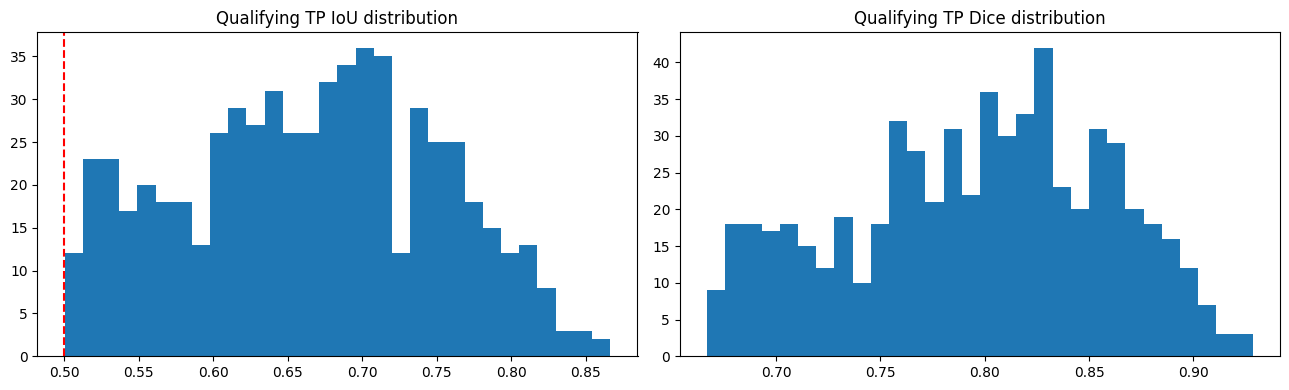

In [17]:
# ============================================================
# FINAL VALIDATION — best checkpoint, COMPLETE validation set, official metric
# ============================================================
if not TRAINING_COMPLETE:
    raise RuntimeError(f"Training is NOT complete ({completed_epochs}/{CFG['epochs']} epochs). "
                       f"Re-run the training cell (it resumes automatically) before final evaluation.")

model.load_state_dict(torch.load(CKPT_BEST, map_location=DEVICE, weights_only=True))
model.eval()
_meta = read_best_meta()
assert _meta is not None and _meta["best_epoch"] == best_epoch, "best checkpoint metadata mismatch"

t_eval = time.time()
per_image, overall, tp_ious, tp_dices = evaluate_validation(
    model, val_ids, CFG["prob_threshold"], desc="FINAL validation (best checkpoint)")
eval_seconds = time.time() - t_eval

expected_val = CFG["debug_n_val"] if DEBUG_MODE else int((split_df.split == "val").sum())
assert overall["n_images_evaluated"] == len(val_ids) == expected_val, \
    "final metrics were NOT computed over the complete validation set"

per_image = per_image.merge(split_df[["img_id", "date", "station"]], on="img_id", how="left")
per_image.to_csv(OUT / "per_image_metrics.csv", index=False)

print(f"Best checkpoint: epoch {best_epoch} (val loss {best_val:.4f}) | "
      f"evaluated {overall['n_images_evaluated']} validation images in {eval_seconds/60:.1f} min")
print(json.dumps(overall, indent=2))

if tp_ious:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].hist(tp_ious, bins=30); axes[0].axvline(0.5, c="r", ls="--")
    axes[0].set_title("Qualifying TP IoU distribution")
    axes[1].hist(tp_dices, bins=30); axes[1].set_title("Qualifying TP Dice distribution")
    plt.tight_layout(); plt.savefig(OUT / "iou_dice_dist.png", dpi=110); plt.show()

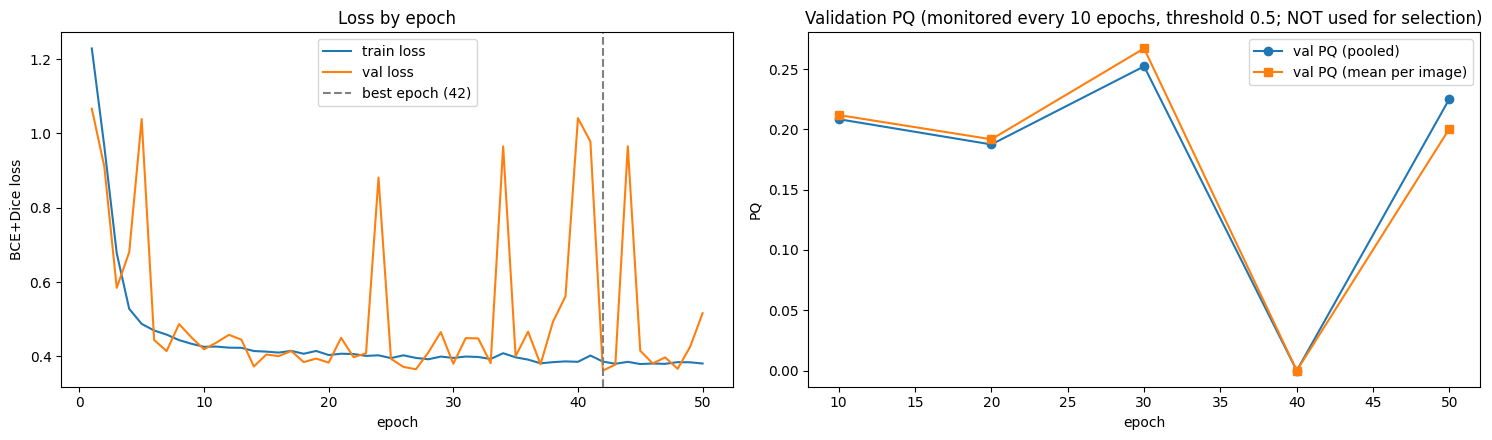

In [18]:
# ============================================================
# TRAINING CURVES
# ============================================================
hd = pd.read_csv(HIST_CSV)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(hd.epoch, hd.train_loss, label="train loss")
axes[0].plot(hd.epoch, hd.val_loss, label="val loss")
axes[0].axvline(best_epoch, c="gray", ls="--", label=f"best epoch ({best_epoch})")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("BCE+Dice loss"); axes[0].legend()
axes[0].set_title("Loss by epoch")

pq = hd.dropna(subset=["val_PQ_pooled"])
if len(pq):
    axes[1].plot(pq.epoch, pq.val_PQ_pooled, "o-", label="val PQ (pooled)")
    axes[1].plot(pq.epoch, pq.val_PQ_mean_per_image, "s-", label="val PQ (mean per image)")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("PQ"); axes[1].legend()
    axes[1].set_title(f"Validation PQ (monitored every {CFG['pq_eval_every']} epochs, "
                      f"threshold {CFG['prob_threshold']}; NOT used for selection)")
else:
    axes[1].text(0.5, 0.5, "no PQ monitoring points", ha="center"); axes[1].axis("off")
plt.tight_layout(); plt.savefig(OUT / "training_curve.png", dpi=110); plt.show()

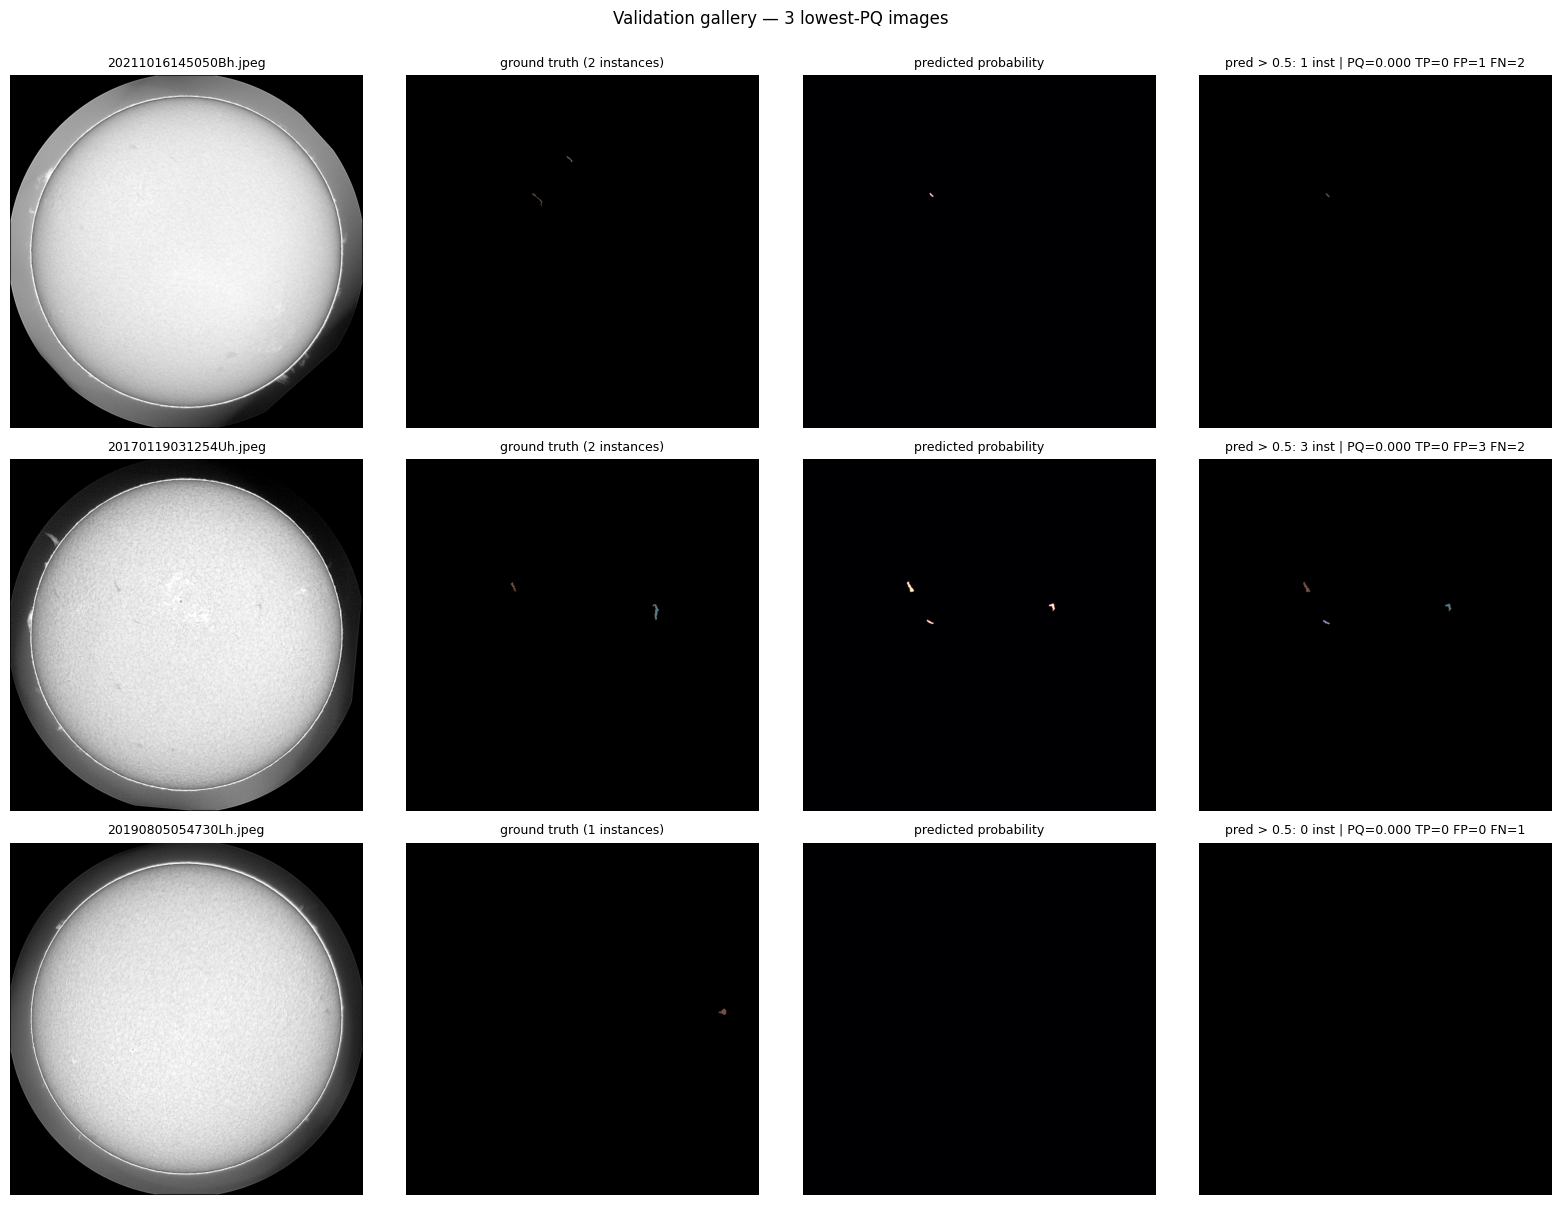

In [19]:
# ============================================================
# VALIDATION PREDICTION GALLERY
# original | ground truth (instances) | predicted probability | predicted instances
# 8 images drawn at random with a fixed seed (not cherry-picked) + the 3 worst-PQ images.
# ============================================================
DISP = 768
_palette = np.random.RandomState(1).rand(512, 3) * 0.8 + 0.2

def _colorize(labels):
    rgb = np.zeros(labels.shape + (3,), np.float32)
    m = labels > 0
    rgb[m] = _palette[labels[m] % len(_palette)]
    return rgb

def _instances_to_labels(masks, shape):
    lab = np.zeros(shape, np.int32)
    for k, m in enumerate(masks, 1):
        lab[m] = k
    return lab

def gallery(ids, fname_out, title):
    fig, axes = plt.subplots(len(ids), 4, figsize=(16, 4 * len(ids)))
    axes = np.atleast_2d(axes)
    for r, img_id in enumerate(ids):
        fname = Path(images_info[img_id]["file_name"]).name
        img = load_image(name_to_path[fname])
        gt = build_gt_masks(img_id)
        prob = predict_image(model, name_to_path[fname], CFG["train_resolution"])
        preds = extract_instances(prob, CFG["prob_threshold"], CFG["min_instance_px"])
        row = per_image[per_image.img_id == img_id].iloc[0]
        lo, hi = np.percentile(img, [1, 99])
        vis = np.clip((img - lo) / max(hi - lo, 1e-6), 0, 1)
        shp = img.shape
        d = lambda a, interp: cv2.resize(a, (DISP, DISP), interpolation=interp)
        axes[r, 0].imshow(d(vis, cv2.INTER_AREA), cmap="gray"); axes[r, 0].set_title(fname, fontsize=9)
        axes[r, 1].imshow(d(_colorize(_instances_to_labels(gt, shp)), cv2.INTER_NEAREST))
        axes[r, 1].set_title(f"ground truth ({len(gt)} instances)", fontsize=9)
        axes[r, 2].imshow(d(prob, cv2.INTER_AREA), cmap="magma", vmin=0, vmax=1)
        axes[r, 2].set_title("predicted probability", fontsize=9)
        axes[r, 3].imshow(d(_colorize(_instances_to_labels(preds, shp)), cv2.INTER_NEAREST))
        axes[r, 3].set_title(f"pred > {CFG['prob_threshold']}: {len(preds)} inst | PQ={row.PQ:.3f} "
                             f"TP={row.TP} FP={row.FP} FN={row.FN}", fontsize=9)
        for a in axes[r]: a.axis("off")
    fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.savefig(OUT / fname_out, dpi=80, bbox_inches="tight"); plt.show()

_rng = random.Random(SEED)
gallery(_rng.sample(list(val_ids), min(8, len(val_ids))), "validation_gallery.png",
        "Validation gallery — random sample (fixed seed)")
gallery(per_image.nsmallest(3, "PQ")["img_id"].tolist(), "validation_gallery_worst3.png",
        "Validation gallery — 3 lowest-PQ images")

In [20]:
# ============================================================
# REPORT + RESULTS CSV + EXPERIMENT LOG + FULL CONFIG
# ============================================================
hd = pd.read_csv(HIST_CSV)
n_done = int(len(hd))
all_done = (n_done == CFG["epochs"]) and TRAINING_COMPLETE
best_row = hd.loc[hd.val_loss.idxmin()]
if not (int(best_row.epoch) == best_epoch and abs(best_row.val_loss - best_val) < 1e-6):
    # rare: crash between "best saved" and "latest saved", then the epoch was re-trained on resume
    RUN_WARNINGS.append(f"history minimum val loss (epoch {int(best_row.epoch)}, {best_row.val_loss:.4f}) "
                        f"differs from baseline_best.pth metadata (epoch {best_epoch}, {best_val:.4f}); "
                        f"report uses the checkpoint that was actually evaluated.")
    print("WARNING:", RUN_WARNINGS[-1])

total_train_s = float(hd.elapsed_train_s.iloc[-1])
avg_epoch_s = float(hd.epoch_time_s.mean())                       # train + val loss only
avg_wall_epoch_s = total_train_s / max(n_done, 1)                 # incl. checkpoint saves + PQ monitoring
def _col_sum(c): return float(hd[c].sum()) if c in hd.columns else float("nan")
data_wait_share = _col_sum("data_wait_s") / max(float(hd.epoch_time_s.sum()), 1e-9)
save_s_total = _col_sum("ckpt_save_s")
gpu_name = torch.cuda.get_device_name(0)

# ---- projection of the FULL run, only meaningful from a PILOT run ----
PROJECTION_TXT = ""
if RUN_MODE == "PILOT" and n_done >= 1:
    pq_t = hd["pq_eval_time_s"].dropna() if "pq_eval_time_s" in hd.columns else []
    per_epoch_core = (total_train_s - (float(pq_t.sum()) if len(pq_t) else 0.0)) / n_done
    n_pq = (50 // CFG["pq_eval_every"]) if CFG["pq_eval_every"] else 0
    pq_each = float(pq_t.mean()) if len(pq_t) else float("nan")
    proj_s = per_epoch_core * 50 + (n_pq * pq_each if len(pq_t) else 0.0)
    PROJECTION_TXT = (f"PROJECTED FULL RUN (50 epochs, rough, from {n_done} pilot epochs): ~{proj_s/3600:.1f} h "
                      f"= {per_epoch_core/60:.1f} min/epoch incl. checkpoint saves + {n_pq} PQ evaluations "
                      f"of ~{pq_each/60:.1f} min each. Epoch 1 includes warm-up, so this is probably a slight "
                      f"over-estimate. Compare with your Kaggle session / quota limits before launching FULL.")

MODE_TITLE = {"SMOKE": "SMOKE TEST (reduced images) — NOT A BASELINE RESULT",
              "PILOT": f"PILOT ({CFG['epochs']} epochs, {CFG['train_resolution']} px) — NOT A BASELINE RESULT",
              "FULL":  f"FULL RUN ({CFG['train_resolution']} px)"}[RUN_MODE]
status = (f"ALL {CFG['epochs']} EPOCHS COMPLETED ({n_done}/{CFG['epochs']})" if all_done
          else f"INCOMPLETE: {n_done}/{CFG['epochs']} epochs")

report = f"""
====================================================================
BASELINE-01 — {MODE_TITLE}
====================================================================
Run status:           {status}
Resumed from checkpoint: {('yes, ' + str(RESUME_EVENTS)) if RESUME_EVENTS else 'no (single uninterrupted session)'}
Date:                 {datetime.datetime.now().isoformat(timespec='seconds')}

---- ACTUAL RESULTS (this model, complete validation set) -----------
Checkpoint evaluated: baseline_best.pth (epoch {best_epoch}, selected by lowest val loss {best_val:.4f})
Validation images:    {overall['n_images_evaluated']}
Probability threshold:{overall['threshold']}  (fixed, not tuned)
PQ (pooled):          {overall['PQ_pooled']:.4f}
PQ (mean per-image):  {overall['PQ_mean_per_image']:.4f}
TP:                   {overall['TP']}
FP:                   {overall['FP']}
FN:                   {overall['FN']}
Mean qualifying IoU:  {overall['mean_tp_iou']:.4f}
Mean qualifying Dice: {overall['mean_tp_dice']:.4f}
One-to-many (GT hit by >1 pred):   {overall['one_to_many']}
Many-to-one (pred hit >1 GT):      {overall['many_to_one']}

---- RUN DETAILS -----------------------------------------------------
Data:                 {DATA_ROOT}
Train images:         {len(train_ids)}
Validation images:    {len(val_ids)}   (date-grouped split, seed {SEED}, hash {SPLIT_HASH})
Training resolution:  {CFG['train_resolution']} x {CFG['train_resolution']}
Model:                {CFG['model']} ({N_PARAMS:,} parameters)
Loss / optimizer:     {CFG['loss']} / Adam (lr {CFG['lr']}, wd {CFG['weight_decay']}), batch {CFG['batch_size']}
Augmentation:         horizontal + vertical flips only
Epochs configured:    {CFG['epochs']} | completed: {n_done}
Best epoch:           {best_epoch} (val loss {best_val:.4f})
Total training time:  {total_train_s/3600:.2f} h  (sum of session compute time incl. checkpoint saves + PQ monitoring; excludes disconnect gaps)
Avg epoch duration:   {avg_epoch_s:.0f} s  (train + val loss only)
Avg wall time/epoch:  {avg_wall_epoch_s:.0f} s  (incl. checkpoint saves and PQ monitoring)
DataLoader wait:      {data_wait_share:.1%} of train+val time  (high => CPU/data-loading bound)
Checkpoint saving:    {save_s_total:.0f} s total (latest every {CFG['ckpt_every']} epochs, best when improved)
{PROJECTION_TXT}
Hardware:             {gpu_name} | GPUs visible {N_GPUS_VISIBLE}, GPUs used 1 | AMP {USE_AMP} (loss/val-loss), PQ inference FP32
Output directory:     {OUT}  (Kaggle: kept only after Save Version)

---- REFERENCE BENCHMARKS (NOT results of this model) ----------------
* Notebook 02 inter-annotator agreement: median pairwise PQ ~ 0.38 between annotation records of
  the same image (a measure of label disagreement). It is NOT a human performance ceiling and was
  computed with a different procedure than this model's validation PQ, so treat comparisons with caution.
* Notebook 02 A8 (40 records): rasterization alone at 1024 px caps PQ at ~0.86 mean; this model
  predicts at 1024 and upsamples to 2048.

---- CAVEATS ----------------------------------------------------------
* The validation set was used both to pick the best-val-loss checkpoint and to report PQ,
  so the reported PQ is slightly optimistic relative to a truly untouched holdout.
* Validation PQ is computed on a single date-grouped split (not cross-validation).
* Warnings: {RUN_WARNINGS if RUN_WARNINGS else 'none'}
====================================================================
"""
print(report)
atomic_write_text(OUT / "baseline_report.txt", report)

res_row = {**{k: v for k, v in CFG.items()}, **overall,
           "n_train": len(train_ids), "n_val": len(val_ids), "debug": DEBUG_MODE,
           "epochs_completed": n_done, "all_epochs_completed": all_done,
           "best_epoch": best_epoch, "best_val_loss": best_val,
           "total_train_seconds": total_train_s, "avg_epoch_seconds": avg_epoch_s,
           "split_hash": SPLIT_HASH}
pd.DataFrame([res_row]).to_csv(OUT / "baseline_results.csv", index=False)

log_path = OUT / "experiment_log.csv"
entry = pd.DataFrame([{
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "experiment_id": CFG["experiment_id"], "model": CFG["model"],
    "train_resolution": CFG["train_resolution"], "loss": CFG["loss"],
    "threshold": CFG["prob_threshold"], "epochs": CFG["epochs"], "epochs_completed": n_done,
    "validation_split": "date-grouped 20%", "n_train": len(train_ids), "n_val": len(val_ids),
    "best_epoch": best_epoch, "best_val_loss": round(best_val, 5),
    "PQ": round(overall["PQ_pooled"], 4), "PQ_mean_per_image": round(overall["PQ_mean_per_image"], 4),
    "TP": overall["TP"], "FP": overall["FP"], "FN": overall["FN"],
    "notes": ({"SMOKE": "debug sanity run (Kaggle)", "PILOT": "pilot: 1024px, 3 epochs, timing rehearsal (Kaggle)",
               "FULL": "first real baseline (1024px, 50ep, Kaggle)"}[RUN_MODE]) if all_done else "INCOMPLETE RUN",
}])
entry.to_csv(log_path, mode="a", header=not log_path.exists(), index=False)

run_config = {
    "cfg": CFG, "seed": SEED, "run_mode": RUN_MODE, "debug_mode": DEBUG_MODE, "resume_enabled": RESUME,
    "resume_events": RESUME_EVENTS, "split_hash": SPLIT_HASH,
    "n_train": len(train_ids), "n_val": len(val_ids),
    "optimizer": f"Adam(lr={CFG['lr']}, weight_decay={CFG['weight_decay']})",
    "n_parameters": N_PARAMS, "amp": USE_AMP,
    "environment": {"python": sys.version.split()[0], "torch": torch.__version__,
                    "gpu": gpu_name, "gpus_visible": N_GPUS_VISIBLE, "gpus_used": 1,
                    "platform": platform.platform()},
    "paths": {"data_root": str(DATA_ROOT), "annotations": str(ANN_PATH), "output_dir": str(OUT),
              "best_checkpoint": str(CKPT_BEST), "latest_checkpoint": str(CKPT_LATEST)},
    "platform_name": "Kaggle Notebooks", "warnings": RUN_WARNINGS,
}
atomic_write_text(OUT / "run_config.json", json.dumps(run_config, indent=2, default=str))

print("Saved files:")
for f in ["baseline_best.pth", "latest_checkpoint.pth", "baseline_results.csv", "per_image_metrics.csv",
          "experiment_log.csv", "training_curve.png", "baseline_report.txt", "training_history.csv",
          "validation_gallery.png", "validation_gallery_worst3.png", "run_config.json",
          "split_metadata.csv"]:
    p = OUT / f
    print(f"  {'OK ' if p.exists() else 'MISSING'}  {p}")
print("\nNOTE: files in /kaggle/working persist only after 'Save Version' (Save & Run All) — "
      "or download them from the Output tab.")


BASELINE-01 — FULL RUN (1024 px)
Run status:           ALL 50 EPOCHS COMPLETED (50/50)
Resumed from checkpoint: no (single uninterrupted session)
Date:                 2026-10-23T12:14:09

---- ACTUAL RESULTS (this model, complete validation set) -----------
Checkpoint evaluated: baseline_best.pth (epoch 42, selected by lowest val loss 0.3619)
Validation images:    139
Probability threshold:0.5  (fixed, not tuned)
PQ (pooled):          0.2881
PQ (mean per-image):  0.2974
TP:                   611
FP:                   1201
FN:                   397
Mean qualifying IoU:  0.6649
Mean qualifying Dice: 0.7955
One-to-many (GT hit by >1 pred):   182
Many-to-one (pred hit >1 GT):      11

---- RUN DETAILS -----------------------------------------------------
Data:                 /kaggle/input/competitions/filament-segmentation-2026
Train images:         568
Validation images:    139   (date-grouped split, seed 42, hash 0cc2d729a5b1)
Training resolution:  1024 x 1024
Model:                UN

In [21]:
# ============================================================
# FINAL SUMMARY — copy this block back to Claude
# ============================================================
print(f"BASELINE-01 FINAL SUMMARY — mode {RUN_MODE}" + ("  (NOT a baseline result)" if RUN_MODE != "FULL" else ""))
print("-" * 60)
print(f"1. All {CFG['epochs']} epochs completed:  {'YES' if all_done else 'NO'} ({n_done}/{CFG['epochs']})")
print(f"2. Train / val images:           {len(train_ids)} / {len(val_ids)}")
print(f"3. Training resolution:          {CFG['train_resolution']}x{CFG['train_resolution']}")
print(f"4. Total runtime / avg epoch:    {total_train_s/3600:.2f} h / {avg_epoch_s:.0f} s (train+val), "
      f"{avg_wall_epoch_s:.0f} s wall incl. saves/monitoring")
print(f"   data-wait share / save time:  {data_wait_share:.1%} / {save_s_total:.0f} s")
if PROJECTION_TXT:
    print("   " + PROJECTION_TXT)
print(f"5. Best epoch / val loss:        {best_epoch} / {best_val:.4f}")
print(f"6. PQ pooled / mean per-image:   {overall['PQ_pooled']:.4f} / {overall['PQ_mean_per_image']:.4f}")
print(f"7. TP / FP / FN:                 {overall['TP']} / {overall['FP']} / {overall['FN']}")
print(f"   mean qualifying IoU / Dice:   {overall['mean_tp_iou']:.4f} / {overall['mean_tp_dice']:.4f}")
print(f"8. One-to-many / many-to-one:    {overall['one_to_many']} / {overall['many_to_one']}")
print(f"9. Outputs:                      {OUT}")
print(f"   best checkpoint:              {CKPT_BEST}")
print(f"10. Warnings/deviations:         {RUN_WARNINGS if RUN_WARNINGS else 'none'}"
      f" | resumed: {bool(RESUME_EVENTS)} | threshold {CFG['prob_threshold']} | AMP {USE_AMP}")

BASELINE-01 FINAL SUMMARY — mode FULL
------------------------------------------------------------
1. All 50 epochs completed:  YES (50/50)
2. Train / val images:           568 / 139
3. Training resolution:          1024x1024
4. Total runtime / avg epoch:    1.62 h / 112 s (train+val), 117 s wall incl. saves/monitoring
   data-wait share / save time:  0.5% / 3 s
5. Best epoch / val loss:        42 / 0.3619
6. PQ pooled / mean per-image:   0.2881 / 0.2974
7. TP / FP / FN:                 611 / 1201 / 397
   mean qualifying IoU / Dice:   0.6649 / 0.7955
8. One-to-many / many-to-one:    182 / 11
9. Outputs:                      /kaggle/working/full
   best checkpoint:              /kaggle/working/full/baseline_best.pth
10. Warnings/deviations:         none | resumed: False | threshold 0.5 | AMP True
